In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy import signal
import json

import utils

In [2]:
import matplotlib
font = {
                    'serif':  'Computer Modern Roman',
#                     'weight': 200,
                    'size':   30}

matplotlib.rc('font', **font)
plt.rc('text', usetex=True)

In [3]:
logdm2_list = np.asarray(np.ndarray.tolist(np.arange(-2.10, 2.10, 0.1))+ [2.15])
dm2_list = np.power(10, logdm2_list)  
dm2_list = dm2_list[np.logical_and(dm2_list>.1, dm2_list<50)]
dm2_list = np.append(dm2_list, 50.0)

log_Um4sq_list = np.asarray(np.ndarray.tolist(np.arange(-3., 0., 0.1)))  
Um4sq_list = np.power(10, log_Um4sq_list)
Um4sq_list = Um4sq_list[Um4sq_list<0.50]
Um4sq_list = np.append(Um4sq_list, 0.50)

log_Ut4sq_list = np.asarray(np.ndarray.tolist(np.arange(-3., 0., 0.2)))   
Ut4sq_list = np.power(10, log_Ut4sq_list)  
Ut4sq_list = np.insert(Ut4sq_list, 0, 0.)
Ut4sq_list = Ut4sq_list[Ut4sq_list<0.50]
Ut4sq_list = np.append(Ut4sq_list, 0.50)

d24_list = [np.pi]

## Frequentist

In [4]:
data = np.load("/home/adiaz/Cascades/th34/FitsToData/BlindFit/llhs.npy")

In [5]:
dir_nseed_4 = "/data/ana/SterileNeutrino/IC86/HighEnergy/Analysis/th34/Fits/FitToData/n_seeds_4/"
dir_CV =  "/data/ana/SterileNeutrino/IC86/HighEnergy/Analysis/th34/Fits/FitToData/n_seeds_-1/"
suffix = '_Data_IC86.All_cut_everything_platinum_LT_240747841.json'
null_llh = utils.get_llh(dir_nseed_4+ "Ut4sq_0.000000/0_0.000000_0.000000_0.000000_0.000000_0.000000_0.000000" + suffix)
null_llh_CV = utils.get_llh(dir_CV+ "Ut4sq_0.000000/0_0.000000_0.000000_0.000000_0.000000_0.000000_0.000000" + suffix)

In [6]:
CL = [11.345, 7.815, 6.251]
CL_label = ["99\%", "95\%", "90\%"]
linestyles = ['dotted', 'solid', 'dashed']

arg_min = np.unravel_index(data[:,:,3].argmin(), data[:,:,3].shape)
dm2_min, Um4sq_min, Ut4sq_min, llh_min =data[arg_min]
th14_min, th24_min, th34_min = utils.Usq_to_thetas(Um4sq = Um4sq_min, Ut4sq = Ut4sq_min)
print(th14_min, th24_min, th34_min)
print(dm2_min, Um4sq_min, Ut4sq_min)
print(dm2_min, utils.Um4sqtosin22th(Um4sq_min), Ut4sq_min)

0.0 0.2008744066784862 0.08115183801599558
5.01187233627275 0.03981071705534985 0.006309573444801942
5.01187233627275 0.1529032954515549 0.006309573444801942


/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_7_x86_64/lib/python3.7/site-packages/matplotlib/contour.py:1230: UserWarning: No contour levels were found within the data range.
  warnings.warn("No contour levels were found"


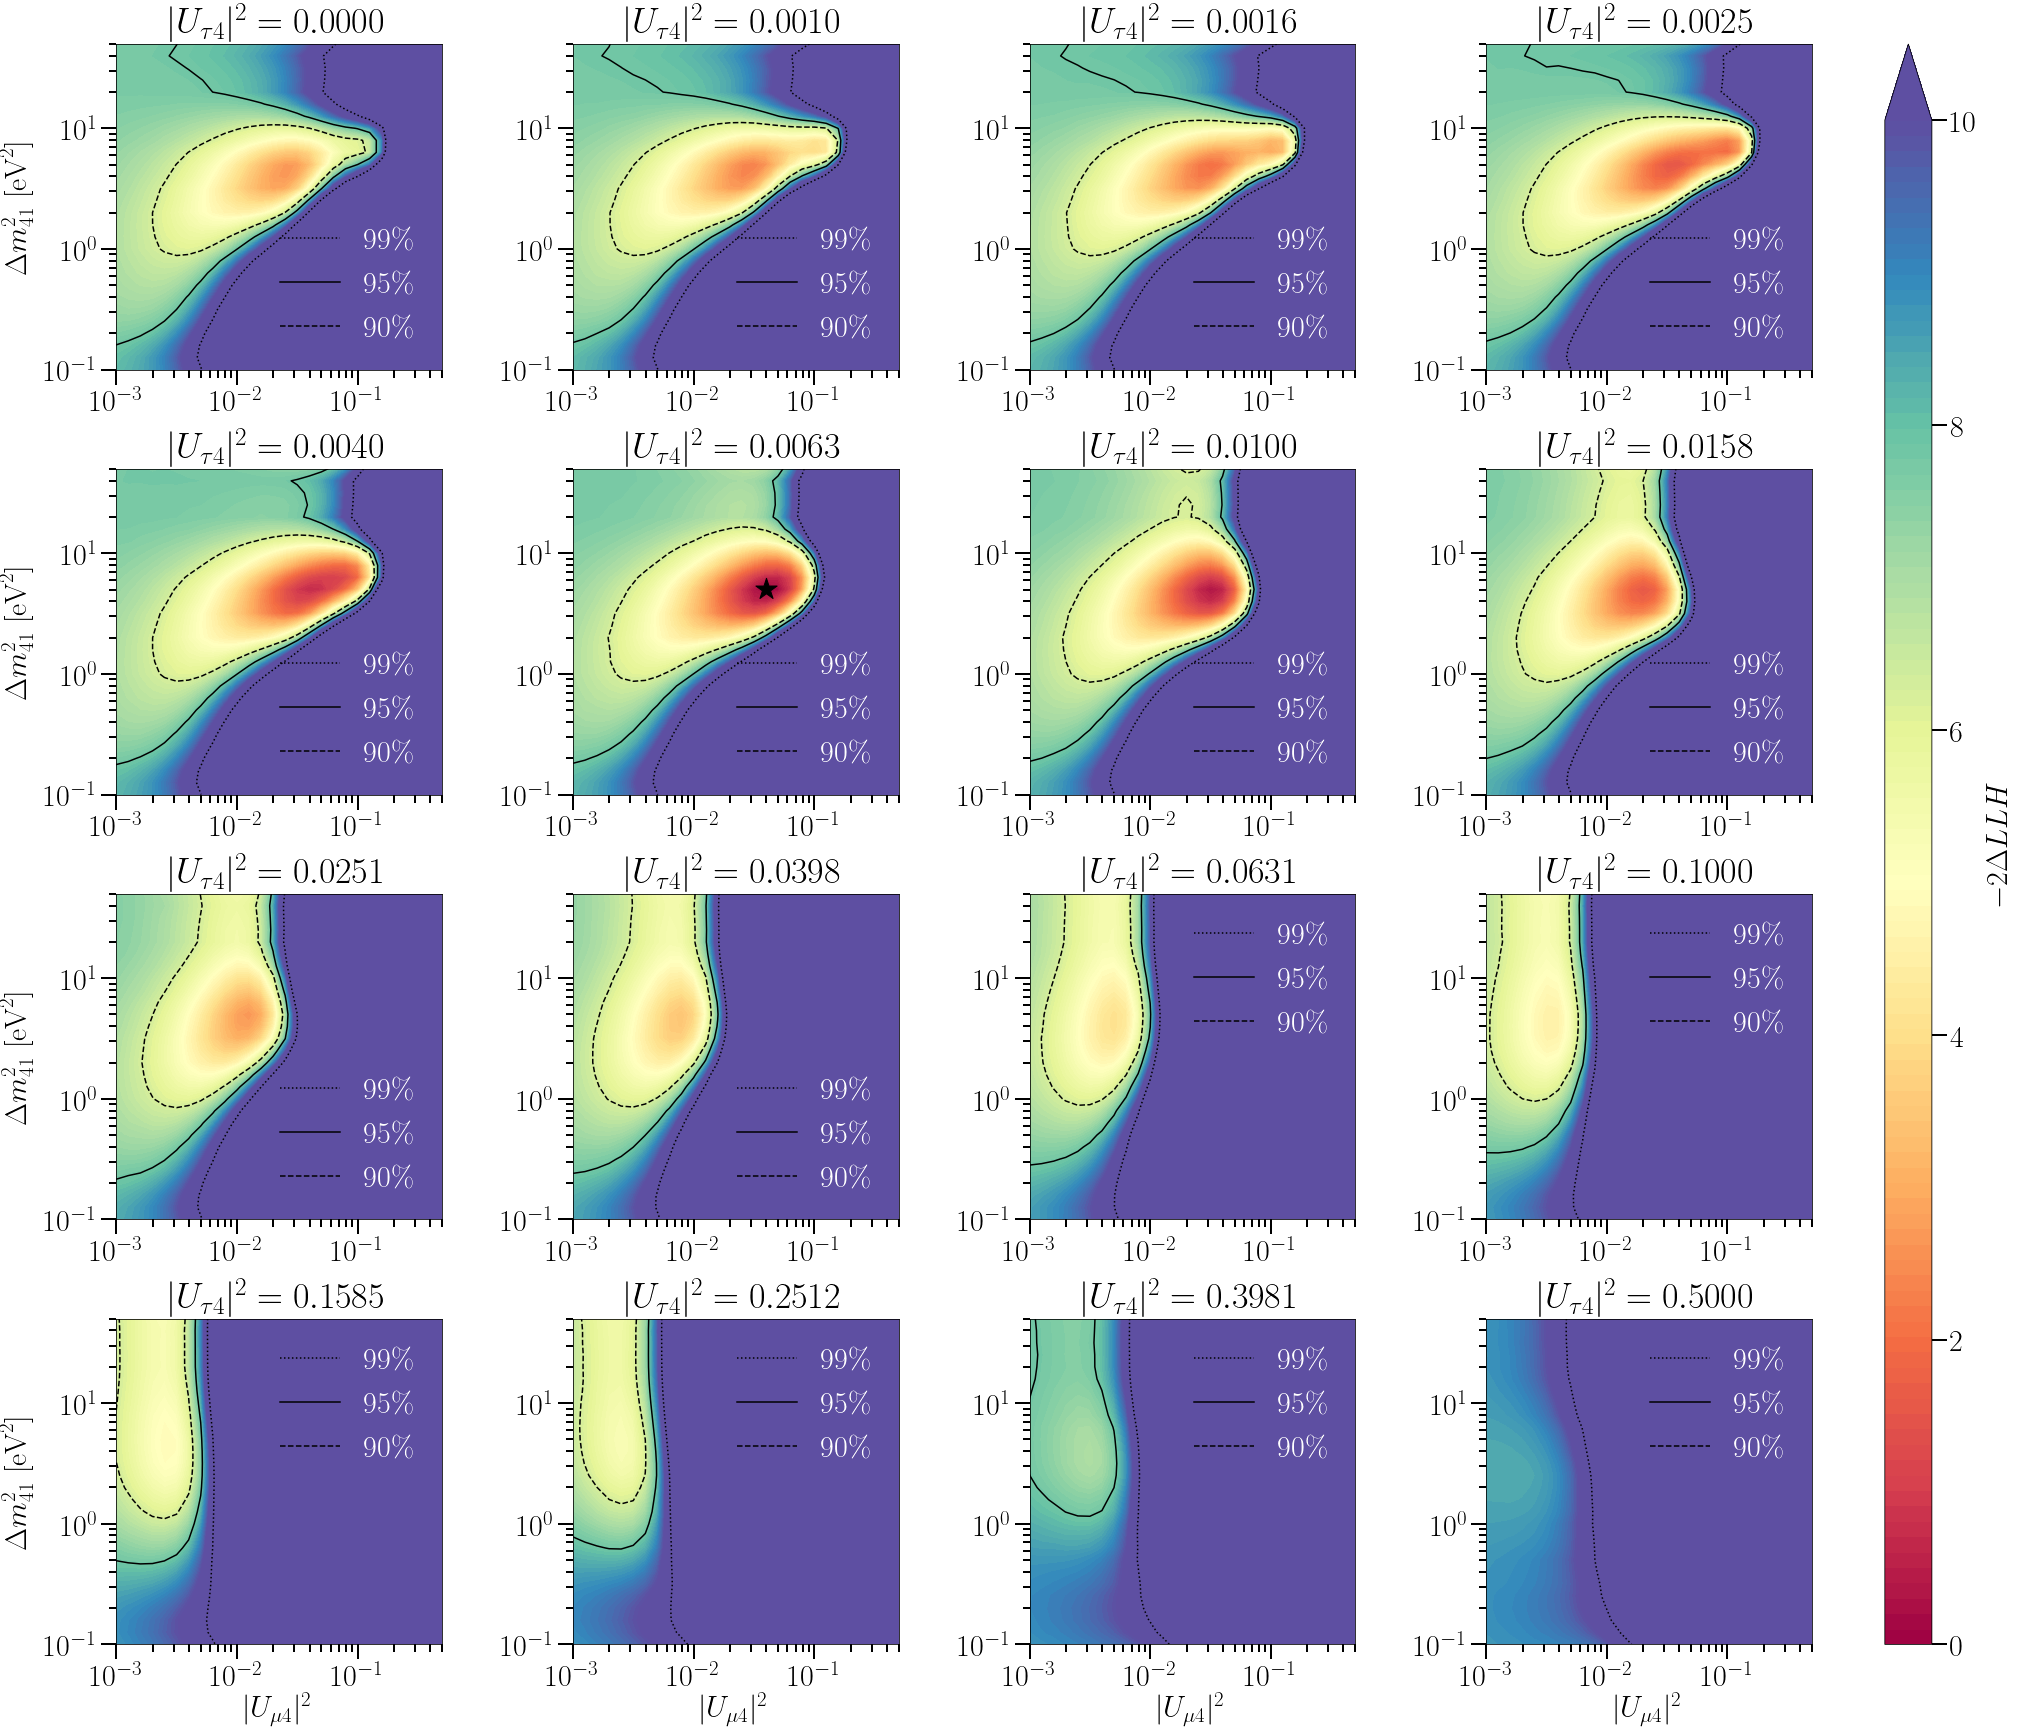

<Figure size 432x288 with 0 Axes>

In [7]:
xscale = 1./0.85
size = 6
columns = 4
rows = int(np.ceil(len(Ut4sq_list)/columns))


x_list = Um4sq_list
x_label = r"$|U_{\mu 4}|^{2}$"
x_min = Um4sq_min
fig, axes = plt.subplots(rows, columns, figsize=(xscale*size*columns,size*rows), constrained_layout=True)

#     fig.suptitle()

for i in range(rows*columns):
    ax = axes[i//columns][i%columns]

    if i > len(Ut4sq_list)-1:
        ax.axis('off')
        continue
    ax.set_title(r'$|U_{{\tau 4}}|^2 = {:.4f}$'.format(Ut4sq_list[i]))

    ax.set_xlim(x_list.min(), x_list.max())
    ax.set_ylim(dm2_list.min(), dm2_list.max())

    z = 2*(data[i,:,3] - data[:,:,3].min())
    cf = utils.make_exclusion_colorful(dm2_list, x_list, z,
                  ax = ax, \
                            levels = np.linspace(0,10,100), cmap='Spectral', extend='max')

    for critical, linestyle, cl_label in zip(CL, linestyles, CL_label):


        utils.make_exclusion(dm2_list, x_list, z, \
                   critical, r'${}$'.format(cl_label),
                    ax = ax, color = 'k', linestyle = linestyle)

    if i//columns == columns-1:
        ax.set_xlabel(x_label)

    if i%columns == 0:
        ax.set_ylabel(r"$\Delta m_{41}^2~[\textrm{eV}^2]$")

    ax.tick_params(axis='both', which='major')
    ax.tick_params(axis='both', which='major', length = 15, width = 2)
    ax.tick_params(axis='both', which='minor', length = 7.5, width = 2)

    ax.set_aspect('equal')

    if Ut4sq_list[i] == Ut4sq_min:

        ax.scatter(x_min, dm2_min, c = 'k', marker="*", s = 500)

    leg = ax.legend(frameon=False)
    for text in leg.get_texts():
        plt.setp(text, color = 'w')

cbar = fig.colorbar(cf, ax=axes,ticks = np.linspace(0,10,6), aspect = 40)
cbar.set_label(r"$-2\Delta LLH$",)
cbar.ax.tick_params(which='major', length = 15, width = 2)
cbar.ax.tick_params(which='minor', length = 7.5, width = 2)

plt.draw()
plt.savefig("frequentist.pdf")
plt.show()
plt.clf()


## Brazil 

In [8]:
n_realizations = 1000
dirbase = "/data/ana/SterileNeutrino/IC86/HighEnergy/Analysis/th34/Fits/BrazilPlot/0_0.000000_0.000000_0.000000_0.000000_0.000000_0.000000/fits/"

filename = dirbase + "Realization_0/Realization_0.npy"
points = np.load(filename)

realizations = np.zeros((n_realizations, *points.shape))

llh_mins = np.zeros(n_realizations)
d2llhs = np.zeros(n_realizations)
null_llhs = np.zeros(n_realizations)
for i in range(n_realizations):
    filename = dirbase + "Realization_{}/Realization_{}.npy".format(i,i)
    points = np.load(filename)
    realizations[i] = points
    
allowed = np.zeros(points[:,:,0].shape)
# critical=7.815
critical=11.345
for i_Ut4sq in range(len(Ut4sq_list)):
    
    for i_realization in range(n_realizations):
        allowed_temp = 2*(realizations[i_realization][i_Ut4sq,:,3]-realizations[i_realization][:,:,3].min()
    ) < critical
        allowed[i_Ut4sq] += allowed_temp
    

/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_7_x86_64/lib/python3.7/site-packages/matplotlib/figure.py:2117: UserWarning: This figure was using constrained_layout==True, but that is incompatible with subplots_adjust and or tight_layout: setting constrained_layout==False. 
  warnings.warn("This figure was using constrained_layout==True, "


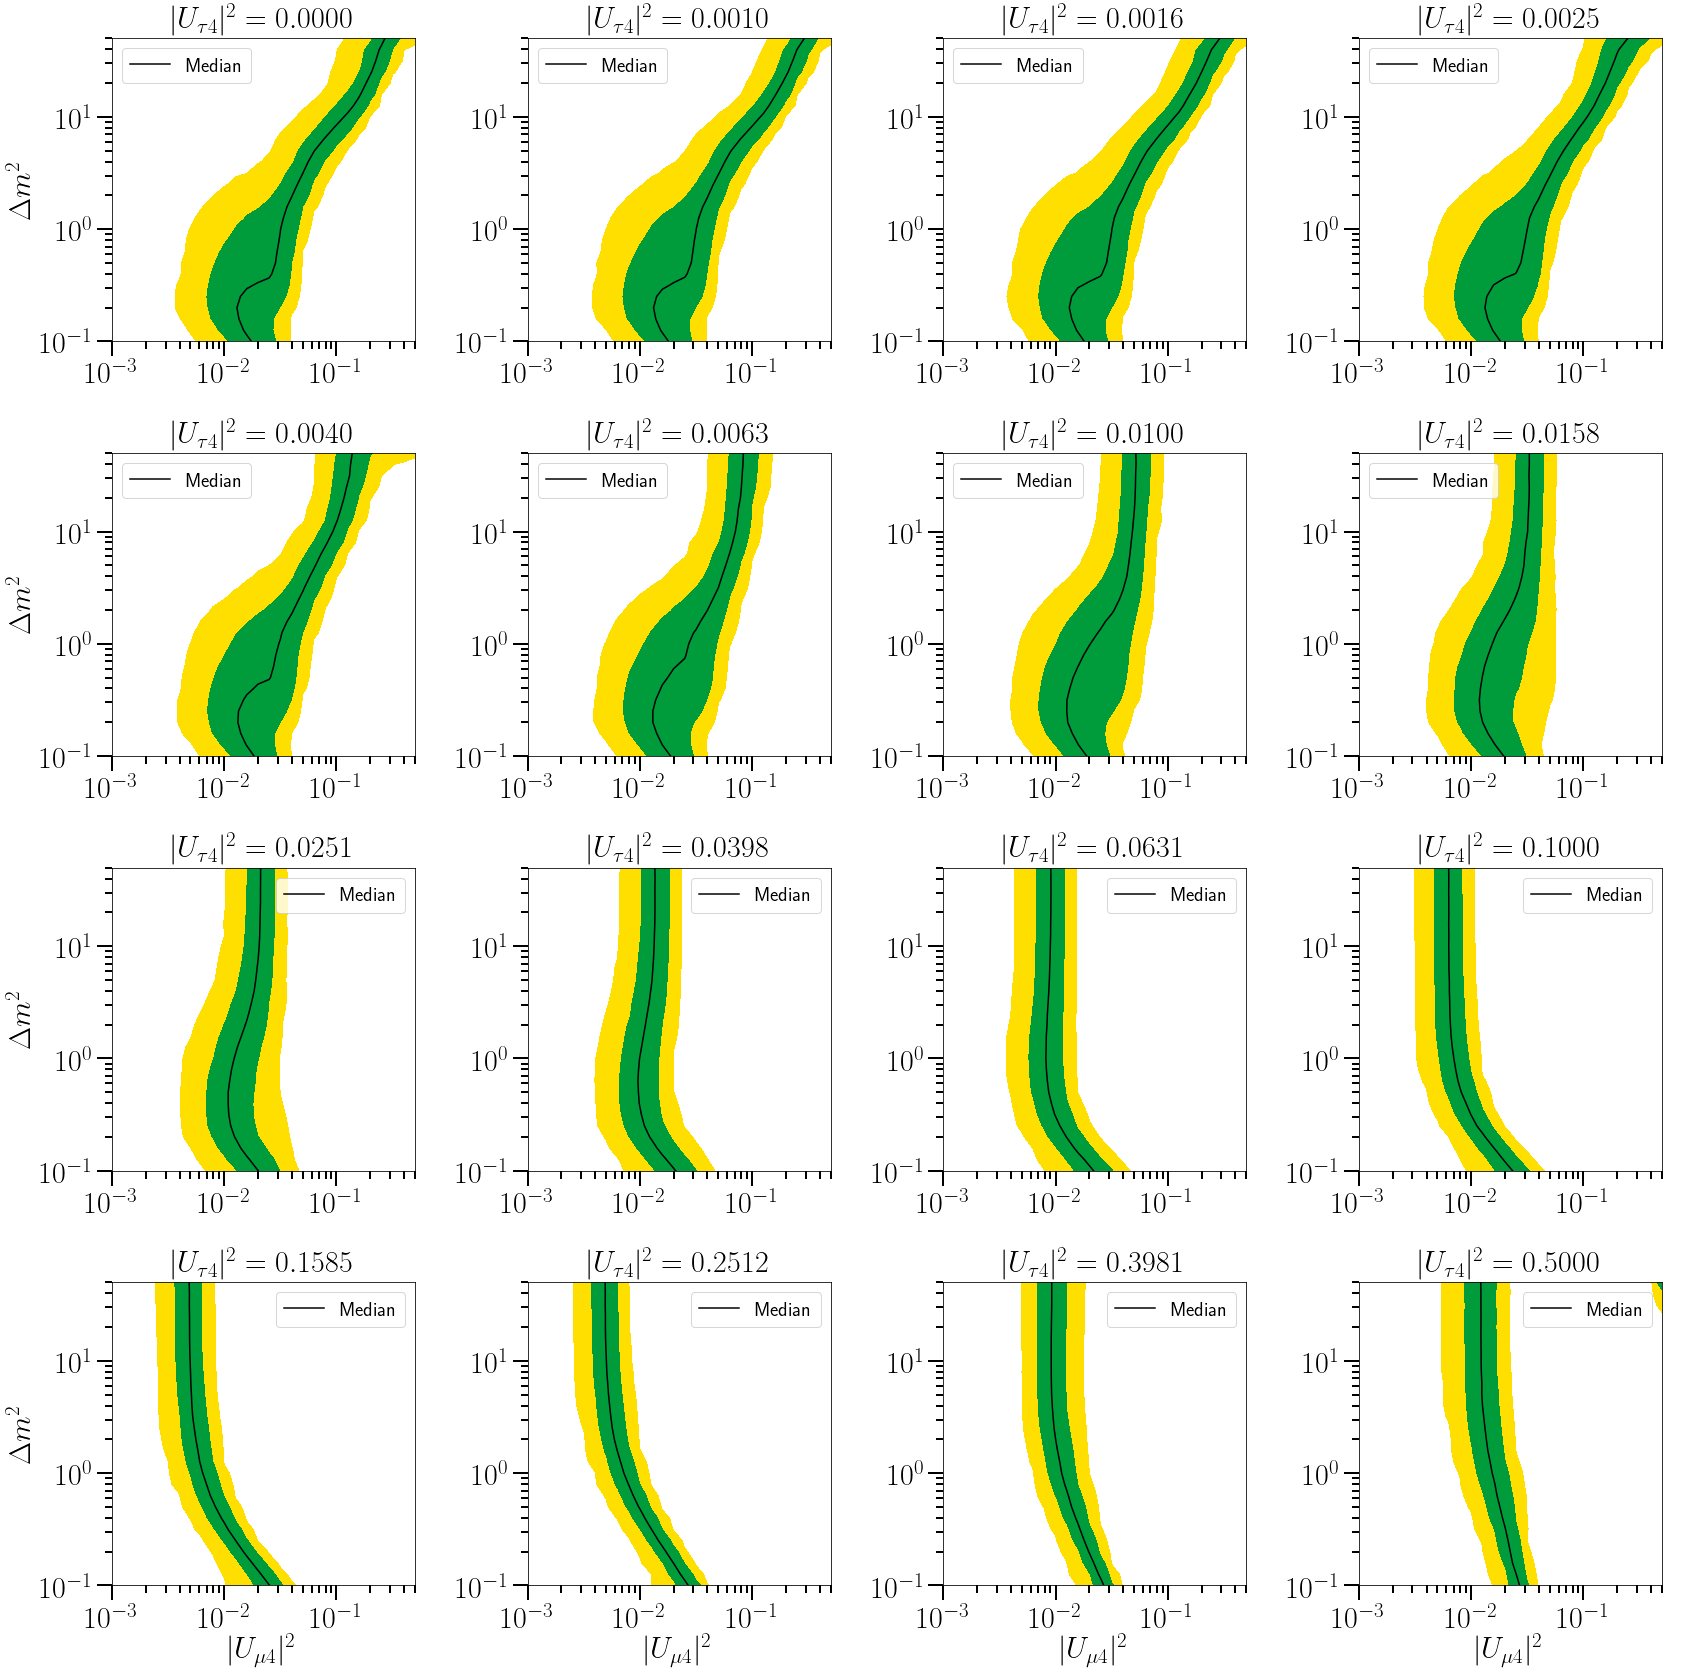

In [13]:
xscale = 1.
size = 6
columns = 4
rows = int(np.ceil(len(Ut4sq_list)/columns))

fig, axes = plt.subplots(rows, columns, figsize=(xscale*size*columns,size*rows), constrained_layout=True)

for i in range(rows*columns):
    ax = axes[i//columns][i%columns]

#     ax=axes[i]
    if i > len(Ut4sq_list)-1:
        ax.axis('off')
        continue
    
    if i//columns == rows-1:
        ax.set_xlabel(r"$|U_{\mu 4}|^{2}$", size = 30)
        
    if i%columns == 0:
        ax.set_ylabel(r"$\Delta m^2$", size = 30)
        
    ax.set_title(r'$|U_{{\tau 4}}|^2 = {:.4f}$'.format(Ut4sq_list[i]), size = 30)
    ax.set_xlim(Um4sq_list.min(),.5)
    ax.set_ylim(.1,50)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_aspect('equal')
    utils.make_exclusion(dm2_list, Um4sq_list, allowed[i], \
               .5*n_realizations,
               ax = ax, \
                     color = 'k', label = "Median")
    
    
    ax.contourf(Um4sq_list, dm2_list, allowed[i].reshape(len(dm2_list), len(Um4sq_list)), levels =
               [0.01*(100-95.45)/2*n_realizations, 
                0.01*(100-68.72)/2*n_realizations, 
                0.01*(100-(100-68.72)/2)*n_realizations,
                0.01*(100-(100-95.45)/2)*n_realizations], colors = ['#ffdf00', '#009c3b', '#ffdf00'])
    
    ax.tick_params(axis='both', which='major', labelsize=30)
    ax.tick_params(axis='both', which='major', length = 15, width = 2)
    ax.tick_params(axis='both', which='minor', length = 7.5, width = 2)

    
    ax.legend(fontsize = 20)
    

plt.tight_layout()
plt.show()

## At best fit Ut4sq

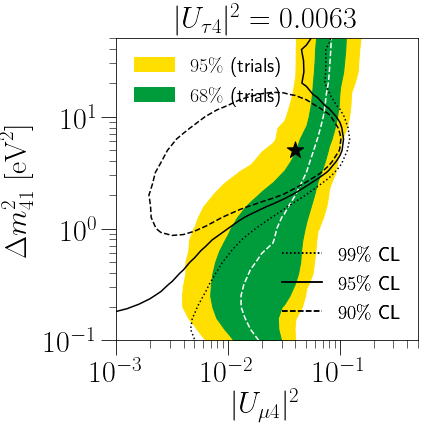

In [15]:
import scipy.interpolate 

def interpolate(list1, list2):
    
    x1 = list1[:,0]
    y1 = list1[:,1]
    x2 = list2[:,0]
    y2 = list2[:,1]
    
    interp1 = scipy.interpolate.interp1d(y1, x1)
    interp2 = scipy.interpolate.interp1d(y2, x2)

    y = np.unique(np.concatenate((y1,y2)))
        
    x1_interpolated = interp1(y)
    x2_interpolated = interp2(y)
    
    return y, x1_interpolated, x2_interpolated
fig, ax = plt.subplots(figsize = (6,6), constrained_layout = True)
i=5

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e-1, 50)
ax.set_xlim(1e-3, 0.5)
ax.set_aspect('equal')
ax.set_title(r'$|U_{{\tau 4}}|^2 = {:.4f}$'.format(Ut4sq_min), size = 30)

utils.make_exclusion(dm2_list, Um4sq_list, allowed[i], \
           .5*n_realizations,
           ax = ax, \
                 color = 'w', linestyle = '--',)

p_95_high = ax.contourf(np.log10(Um4sq_list), np.log10(dm2_list), allowed[i].reshape(len(dm2_list), len(Um4sq_list)), levels =
           [-1,0.01*(100-95.45)/2*n_realizations,n_realizations+100], alpha = 0.)
p_95_low = ax.contourf(np.log10(Um4sq_list), np.log10(dm2_list), allowed[i].reshape(len(dm2_list), len(Um4sq_list)), levels =
           [-1,0.01*(100-(100-95.45)/2)*n_realizations,n_realizations+100], alpha = 0.)

dat0_95_high= np.concatenate((np.array(p_95_high.allsegs[0][0])[:2], np.array(p_95_high.allsegs[0][0])[45:]))
dat0_95_low= np.array(p_95_low.allsegs[0][0])[57:-1]
y, x1, x2 = interpolate(dat0_95_low, dat0_95_high)
# plt.plot(10**dat0_95_high[:,0], 10**dat0_95_high[:,1])
c_95 = ax.fill_betweenx(10**y, 10**x1, 10**x2, color = '#ffdf00', label =  "95\% (trials)")

p_68_high = ax.contourf(np.log10(Um4sq_list), np.log10(dm2_list), allowed[i].reshape(len(dm2_list), len(Um4sq_list)), levels =
           [-1,0.01*(100-68.72)/2*n_realizations,n_realizations+100], alpha = 0.)
p_68_low = ax.contourf(np.log10(Um4sq_list), np.log10(dm2_list), allowed[i].reshape(len(dm2_list), len(Um4sq_list)), levels =
           [-1,0.01*(100-(100-68.72)/2)*n_realizations,n_realizations+100], alpha = 0.)


dat0_68_high= np.array(p_68_high.allsegs[0][0])[46:-1]
dat0_68_low= np.concatenate((np.array(p_68_low.allsegs[0][0])[:2], np.array(p_68_low.allsegs[0][0])[55:]))
y, x1, x2 = interpolate(dat0_68_low, dat0_68_high)
c_68 = ax.fill_betweenx(10**y, 10**x1, 10**x2, color = '#009c3b', label =  "68\% (trials)")

leg1 = ax.legend([c_95, c_68], ["$95\%$ (trials)","$68\%$ (trials)"], loc = 'upper left', fontsize = 20, frameon=False)

c = []
for critical, linestyle, cl_label in zip(CL, linestyles, CL_label):
    z = 2*(data[i,:,3] - data[:,:,3].min())
    temp= utils.make_exclusion(dm2_list, Um4sq_list, z, critical, ax = ax,
                        color = 'k', linestyle = linestyle)
    c.append(temp[0])
    
leg2 = ax.legend(c, ["$99\%$ CL", "$95\%$ CL", "$90\%$ CL"], loc='lower right', fontsize = 20, frameon=False)
# ax.legend(fontsize = 20, frameon = False, loc='upper left')
ax.set_ylabel(r"$\Delta m_{41}^2~[\textrm{eV}^2]$", size = 30)
ax.set_xlabel(r"$|U_{\mu 4}|^{2}$", size = 30)

ax.scatter(Um4sq_min, dm2_min, c = 'k', marker="*", s = 300)

ax.tick_params(axis='both', which='major', length = 15)
ax.tick_params(axis='both', which='minor', length = 7.5)
    
ax.add_artist(leg1)
ax.add_artist(leg2)

plt.draw()
plt.savefig("frequentist_Ut4sq_0.0063.pdf")
plt.show()